<h2>Modelling: Future Price Direction 3 (XGBoost)

<h3>Data Preparation

In [2]:
# Load pre split data:
from project_paths import RAW_DATA_PATH
import pandas as pd

from bta_direction_functions import add_direction
print(RAW_DATA_PATH)

raw_data = pd.read_pickle(RAW_DATA_PATH)
nd_data = raw_data.copy()
nd_data.head()

C:\Users\cochr\Data Science Projects\vlXsnPPgKKnWqEJB\data\raw\btcusd_data.pkl


Price,Date,Close,High,Low,Open,Volume
0,2014-09-17,457.334015,468.174011,452.421997,465.864014,21056800
1,2014-09-18,424.440002,456.859985,413.104004,456.859985,34483200
2,2014-09-19,394.795990,427.834991,384.532013,424.102997,37919700
3,2014-09-20,408.903992,423.295990,389.882996,394.673004,36863600
4,2014-09-21,398.821014,412.425995,393.181000,408.084991,26580100


In [4]:
data_20 = add_direction(data=nd_data, shift=20, price="Close")
data_20 = data_20.drop(columns=["Date"])
data_20.head()

Price,Close,High,Low,Open,Volume,Direction_20
0,457.334015,468.174011,452.421997,465.864014,21056800,0
1,424.440002,456.859985,413.104004,456.859985,34483200,0
2,394.795990,427.834991,384.532013,424.102997,37919700,0
3,408.903992,423.295990,389.882996,394.673004,36863600,0
4,398.821014,412.425995,393.181000,408.084991,26580100,0


In [6]:
from bta_direction_functions import add_EMA, add_SMA

Let's add _5 (1 week), _10 (2 week_), _20 (1 month) SMAs and EMAs. Leave out MACD, RSI and ATR.

In [7]:
data_20 = add_SMA(data=data_20,n=5,price="Close")
data_20 = add_SMA(data=data_20,n=10,price="Close")
data_20 = add_SMA(data=data_20,n=20,price="Close")

data_20 = add_EMA(data=data_20,n=5,price="Close")
data_20 = add_EMA(data=data_20,n=10,price="Close")
data_20 = add_EMA(data=data_20,n=20,price="Close")

In [9]:
data_20 = data_20.dropna().copy() # Drop NA rows
data_20.head()

Price,Close,High,Low,Open,Volume,Direction_20,SMA_5,SMA_10,SMA_20,EMA_5,EMA_10,EMA_20
19,330.079010,345.134003,302.559998,320.389008,79011800,1,342.807800,363.676599,389.910399,341.195946,359.626329,383.883180
20,336.187012,339.247009,320.481995,330.584015,49199900,1,335.030804,357.343301,383.853049,339.526301,355.364635,379.340688
21,352.940002,354.364014,327.187988,336.115997,54736300,1,333.716406,354.919202,380.278049,343.997535,354.923793,376.826337
22,365.026001,382.726013,347.687012,352.747986,83641104,0,340.948407,353.875101,378.789549,351.007024,356.760558,375.702495
23,361.562012,375.066986,352.963013,364.687012,43665700,0,349.158807,351.336902,376.422450,354.525353,357.633549,374.355783


<h3>Feature Selection

In [11]:
X = data_20.drop(columns=["Direction_20"])
y = data_20["Direction_20"]
features = list(X.columns)
print(features)

Index(['Close', 'High', 'Low', 'Open', 'Volume', 'SMA_5', 'SMA_10', 'SMA_20',
       'EMA_5', 'EMA_10', 'EMA_20'],
      dtype='str', name='Price')


eta-Squared

In [12]:
from feature_selection import eta_squared

In [13]:
eta_results = pd.Series(
    {
        feature: eta_squared(
            y,
            X[feature],
        )
        for feature in features
    },
    name="eta_squared",
).sort_values(ascending=False)

print(eta_results)

SMA_20    0.014629
EMA_20    0.014430
EMA_10    0.013902
SMA_10    0.013814
EMA_5     0.013618
Close     0.013572
SMA_5     0.013566
High      0.013547
Open      0.013450
Low       0.013426
Volume    0.007531
Name: eta_squared, dtype: float64


Mutual Information

In [14]:
from sklearn.feature_selection import mutual_info_classif

In [15]:
mi_scores = mutual_info_classif(
    X,
    y,
    discrete_features=False,
    random_state=13,
)

mi_results = pd.Series(
    mi_scores,
    index=features,
    name="mutual_information",
).sort_values(ascending=False)

print(mi_results)

Price
EMA_10    0.129176
EMA_20    0.123796
SMA_10    0.118062
High      0.117697
SMA_20    0.115455
EMA_5     0.111696
Close     0.105691
Low       0.097512
SMA_5     0.094609
Open      0.088735
Volume    0.006693
Name: mutual_information, dtype: float64


Let's remove Volume, Open, SMA_5, and Low in the pipeline

<h3>XGBoost Pipeline

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

In [20]:
X_train_20, X_test_20, y_train_20, y_test_20 = train_test_split(X, y, test_size=0.15, shuffle=False)

In [22]:
features = list(X.columns) 
fs_20_features = [feature for feature in features if feature not in {"Volume", "Open", "SMA_5", "Low"}]# Important FS features
print(fs_20_features)

['Close', 'High', 'SMA_10', 'SMA_20', 'EMA_5', 'EMA_10', 'EMA_20']


Fitting 5 folds for each of 2000 candidates, totalling 10000 fits
Best parameters: {'classifier__colsample_bytree': np.float64(0.9792210984461991), 'classifier__gamma': np.float64(0.15643002279034923), 'classifier__learning_rate': np.float64(0.1970709524832066), 'classifier__max_depth': 5, 'classifier__min_child_weight': 8, 'classifier__n_estimators': 308, 'classifier__reg_alpha': np.float64(1.1657573892697832), 'classifier__reg_lambda': np.float64(0.5754420717616684), 'classifier__subsample': np.float64(0.612686883541015)}
Best CV ROC-AUC: 0.5795
              precision    recall  f1-score   support

         0.0       0.28      0.05      0.09       348
         1.0       0.44      0.84      0.58       306

    accuracy                           0.42       654
   macro avg       0.36      0.45      0.33       654
weighted avg       0.36      0.42      0.32       654

Test ROC-AUC: 0.4824
      mean_train_roc_auc  mean_test_roc_auc  std_test_roc_auc  \
1635            0.970573         

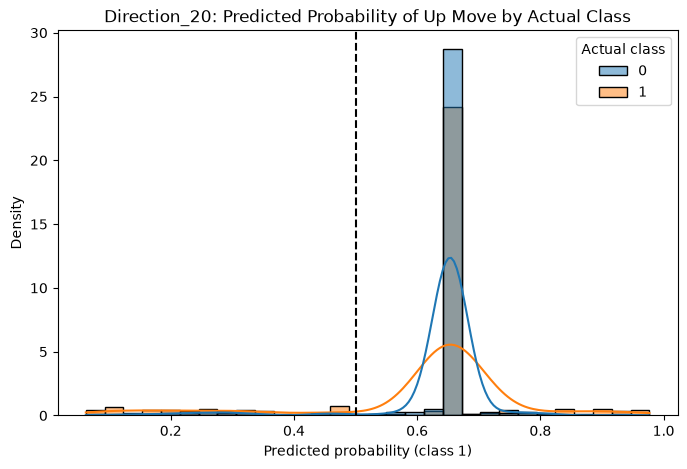

In [25]:
preprocessor_20 = ColumnTransformer([ # XGB doesn't require scalling as it is DT based.
    ("numeric", "passthrough", fs_20_features)
])

xgb_20 = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=13,
    n_jobs=1,  # Avoid nested parallelism
    tree_method="hist"
)

pipeline_20 = Pipeline([
    ("preprocessor", preprocessor_20),
    ("classifier", xgb_20)
])

param_distributions_20 = {
    "classifier__n_estimators": randint(100, 801),
    "classifier__max_depth": randint(2, 7),
    "classifier__learning_rate": loguniform(0.01, 0.2),
    "classifier__subsample": uniform(0.6, 0.4),
    "classifier__colsample_bytree": uniform(0.6, 0.4),
    "classifier__min_child_weight": randint(1, 11),
    "classifier__gamma": uniform(0, 5),
    "classifier__reg_alpha": loguniform(1e-4, 10),
    "classifier__reg_lambda": loguniform(0.1, 100)
}

cv_20 = TimeSeriesSplit(n_splits=5,gap=1)  # Adjust based on target prediction horizon)

random_search_20 = RandomizedSearchCV(
    estimator=pipeline_20,
    param_distributions=param_distributions_20,
    n_iter=2000,
    scoring={
        "roc_auc": "roc_auc",
        "accuracy": "accuracy",
        "f1": "f1"
    },
    refit="roc_auc",
    cv=cv_20,
    n_jobs=-1,
    random_state=13,
    verbose=1,
    return_train_score=True,
    error_score="raise"
)

random_search_20.fit(X_train_20, y_train_20)

pipeline_20 = random_search_20.best_estimator_

print("Best parameters:", random_search_20.best_params_)
print(f"Best CV ROC-AUC: {random_search_20.best_score_:.4f}")

y_pred_20 = pipeline_20.predict(X_test_20)
p_up_20 = pipeline_20.predict_proba(X_test_20)[:, 1]
print(classification_report(y_test_20, y_pred_20))
print(f"Test ROC-AUC: {roc_auc_score(y_test_20, p_up_20):.4f}")
results_20 = pd.DataFrame(random_search_20.cv_results_)

print(
    results_20[
        [
            "mean_train_roc_auc",
            "mean_test_roc_auc",
            "std_test_roc_auc",
            "mean_test_accuracy",
            "mean_test_f1"
        ]
    ]
    .sort_values("mean_test_roc_auc", ascending=False)
    .head(10)
)

fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    x=p_up_20,
    hue=y_test_20.rename("Actual class"),
    bins=30,
    kde=True,
    stat="density",
    common_norm=False,
    ax=ax
)

ax.axvline(0.5, color="k", linestyle="--", label="Threshold (0.5)")
ax.set_title("Direction_20: Predicted Probability of Up Move by Actual Class")
ax.set_xlabel("Predicted probability (class 1)")
plt.show()

Could try an LSTM model?